# Customer Purchase Propensity — từ dữ liệu thô đến kiểm định theo thời gian

**Câu hỏi:** Tại ngày snapshot `s`, một household đã được quan sát có xác suất bao nhiêu để phát sinh ít nhất một basket được ghi nhận trong 7 ngày tiếp theo?

Notebook này theo mạch của notebook churn tham khảo: đặt bài toán → kiểm tra từng bảng → hiểu panel thời gian → dựng nhãn → chia thời gian → tạo feature → phân tích feature → baseline → rolling validation → chọn mô hình → calibration → đánh giá và ứng dụng.

**Phạm vi:** dữ liệu của 2.500 frequent shoppers tại một retailer; kết quả không đại diện cho toàn bộ người tiêu dùng. Một basket được ghi nhận có thể chứa fuel hoặc các dòng giá trị bằng 0; đây là proxy *any recorded basket*, chưa phải định nghĩa giao dịch hợp lệ đã được data owner xác nhận.

**Lưu ý holdout:** tập test ở project này đã được mở trong V2 trước đây. Nó được giữ ngoài mọi bước lựa chọn trong notebook này, nhưng không còn là bằng chứng hoàn toàn mới đối với toàn bộ quá trình dự án.

# 1. Business understanding và định nghĩa target

Hệ thống weekly ranking có thể hỗ trợ ưu tiên contact hoặc lập kế hoạch nhu cầu khi capacity hữu hạn. Score là xác suất mua quan sát được, không đo tác động tăng thêm của coupon.

Với household `h` và cutoff `s`:

$$Y_{h,s}=1 \quad\text{nếu có ít nhất một basket trong }(s,s+7].$$

Feature chỉ dùng dữ liệu tới hết ngày `s`. Household chỉ đủ điều kiện sau lần đầu được quan sát và label phải có đủ 7 ngày theo dõi. Dữ liệu không chứng minh household không mua ở nơi khác.

In [3]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'propensity_v2').exists():
    raise FileNotFoundError('Chạy notebook từ project root hoặc thư mục notebooks')
sys.path.insert(0, str(ROOT / 'src'))
from propensity_v2.config import PropensityV2Config
from propensity_v2.data import load_transactions, enrich_transactions, build_daily_features, load_demographics
from propensity_v2.features import build_modeling_table
from propensity_v2.modeling import temporal_split, rolling_origin_folds, fit_calibrator, calibrate

RAW = ROOT / 'sample_data' / 'dunnhumby'
cfg = PropensityV2Config()
target = cfg.target_column
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 30)
print('Project:', ROOT, '| Target:', target)

Project: C:\Users\kienn\PropensityVSF | Target: target_purchase_next_7d


## Leakage: vì sao snapshot là bắt buộc?

Nếu tính recency đến ngày 711 rồi dự đoán hộ có mua trong 7 ngày cuối hay không, `recency < 7` gần như trực tiếp chứa đáp án. Cần tách thời gian: `[..., s]` cho feature và `(s, s+7]` cho label. Chia ngẫu nhiên các snapshot sau khi tính feature không thay thế được kiểm định tương lai.

# 2. Data understanding — tám bảng nguồn

Kiểm tra schema, độ phủ và khóa trước khi join. `causal_data.csv` có khoảng 36,8 triệu dòng nên được đọc theo chunks; dataset này được audit, chưa đưa vào champion vì thời điểm exposure và availability cần được xác minh.

In [6]:
files = sorted(RAW.glob('*.csv'))
inventory = []
tables = {}
for path in files:
    if path.name in ('transaction_data.csv', 'causal_data.csv'):
        continue
    frame = pd.read_csv(path)
    tables[path.stem] = frame
    inventory.append({'table': path.stem, 'rows': len(frame), 'columns': len(frame.columns),
                      'missing_cells': int(frame.isna().sum().sum()),
                      'exact_duplicate_rows': int(frame.duplicated().sum())})
transactions = load_transactions(RAW)
inventory.append({'table': 'transaction_data', 'rows': len(transactions),
                  'columns': len(transactions.columns),
                  'missing_cells': int(transactions.isna().sum().sum()),
                  'exact_duplicate_rows': int(transactions.duplicated().sum())})
causal_rows = sum(len(chunk) for chunk in pd.read_csv(RAW / 'causal_data.csv',
                  usecols=['PRODUCT_ID'], chunksize=1_000_000))
inventory.append({'table': 'causal_data', 'rows': causal_rows, 'columns': 5,
                  'missing_cells': np.nan, 'exact_duplicate_rows': np.nan})
display(pd.DataFrame(inventory).sort_values('rows', ascending=False))

,table,rows,columns,missing_cells,exact_duplicate_rows
7,causal_data,36786524,5,NaN,NaN
6,transaction_data,2595732,12,0.0,0.0
2,coupon,124548,3,0.0,5164.0
5,product,92353,7,0.0,0.0
1,campaign_table,7208,3,0.0,0.0
3,coupon_redempt,2318,4,0.0,0.0
4,hh_demographic,801,8,0.0,0.0
0,campaign_desc,30,4,0.0,0.0


`NaN` trong inventory của causal data nghĩa là chưa tính ở cell này, không phải bằng 0. Không xóa duplicate coupon mapping một cách tùy tiện trước khi hiểu semantics.

In [8]:
display(transactions.head())
display(transactions.dtypes.to_frame('dtype').T)
display(transactions.isna().sum().to_frame('nulls').T)
print('Rows / households / baskets:', len(transactions),
      transactions.household_key.nunique(), transactions.BASKET_ID.nunique())
print('Day range:', transactions.DAY.min(), '–', transactions.DAY.max())
print('Exact duplicate transaction rows:', transactions.duplicated().sum())

Rows / households / baskets: 2595732 2500 276484
Day range: 1 – 711
Exact duplicate transaction rows: 0


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
dtype,int32,int64,int16,int64,int32,float32,int32,float32,int16,int16,float32,float32


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
nulls,0,0,0,0,0,0,0,0,0,0,0,0


## Kiểm tra product, household và promotion trước khi nối

Product phải là many-to-one theo `PRODUCT_ID`. Demographic chỉ là enrichment tùy chọn: file không cung cấp thời điểm hiệu lực, vì vậy không thể khẳng định thông tin đã sẵn có tại từng cutoff. Campaign assignment cũng không đồng nghĩa hộ đã thực sự nhìn thấy thông điệp.

In [10]:
product = tables['product']
demo = tables['hh_demographic']
campaign = tables['campaign_table']
campaign_desc = tables['campaign_desc']
coupon = tables['coupon']
redemption = tables['coupon_redempt']
checks = {
    'product duplicate keys': product.PRODUCT_ID.duplicated().sum(),
    'transaction product match rate': transactions.PRODUCT_ID.isin(product.PRODUCT_ID).mean(),
    'demographic household coverage': transactions.household_key.drop_duplicates().isin(demo.household_key).mean(),
    'campaign household coverage': transactions.household_key.drop_duplicates().isin(campaign.household_key).mean(),
    'redemption coupon match rate': redemption.COUPON_UPC.isin(coupon.COUPON_UPC).mean(),
}
redemption_windows = redemption.merge(campaign_desc[['CAMPAIGN','START_DAY','END_DAY']],
                                     on='CAMPAIGN', how='left', validate='many_to_one')
checks['redemption in campaign window'] = redemption_windows.DAY.between(
    redemption_windows.START_DAY, redemption_windows.END_DAY).mean()
display(pd.Series(checks, name='value').to_frame())
assert checks['product duplicate keys'] == 0
assert checks['transaction product match rate'] == 1

,value
product duplicate keys,0.0000
transaction product match rate,1.0000
demographic household coverage,0.3204
campaign household coverage,0.6336
redemption coupon match rate,1.0000
redemption in campaign window,1.0000


**Diễn giải:** product join được kiểm chứng trên dữ liệu; demographic coverage và marketing coverage là các đặc điểm của mẫu, không chứng minh đại diện cho population. Các bảng coupon/campaign chỉ tạo giả thuyết, không chứng minh tác động nhân quả.

## Sanity check: quantity không đồng nhất giữa department

Giá trị rất lớn tập trung ở fuel/miscellaneous. Không cộng `QUANTITY` xuyên department như một số lượng món duy nhất; notebook sử dụng basket, số dòng và spend.

In [13]:
large_quantity = transactions.loc[transactions.QUANTITY > 100, ['PRODUCT_ID','QUANTITY']].merge(
    product[['PRODUCT_ID','DEPARTMENT']], on='PRODUCT_ID', how='left', validate='many_to_one')
display(large_quantity.groupby('DEPARTMENT').QUANTITY.agg(['size','median','max']).sort_values('size', ascending=False).head(10))
print('Rows QUANTITY > 100:', len(large_quantity), '| max:', transactions.QUANTITY.max())

Rows QUANTITY > 100: 23136 | max: 89638


,size,median,max
DEPARTMENT,,,
KIOSK-GAS,20267,10551.0,89638
MISC SALES TRAN,2868,12504.5,85055
PRODUCE,1,144.0,144


# 3. Data exploration — panel thời gian và nhãn

Trước khi gán nhãn âm, cần kiểm tra coverage của cửa sổ outcome. Bản thân việc không có basket trong retailer này không đồng nghĩa household không mua ở nơi khác.

,first_observed_day
count,2500.000000
mean,65.941200
std,39.152355
min,1.000000
25%,36.000000
50%,69.000000
75%,95.000000
95%,115.000000
max,671.000000


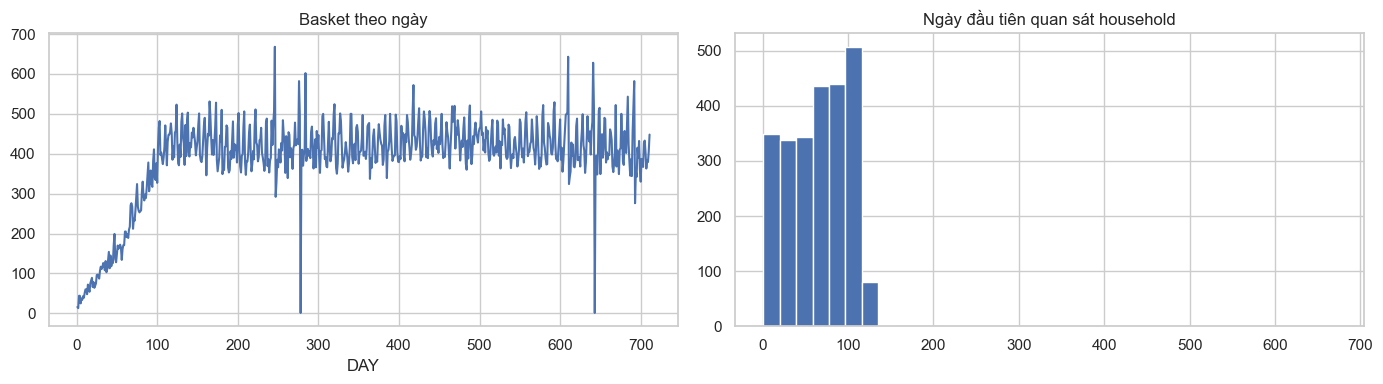

In [15]:
basket = transactions.groupby(['household_key','BASKET_ID','DAY'], as_index=False).agg(
    spend=('SALES_VALUE','sum'), lines=('PRODUCT_ID','size'))
daily_volume = basket.groupby('DAY').agg(baskets=('BASKET_ID','nunique'),
                                         households=('household_key','nunique'))
first_day = transactions.groupby('household_key').DAY.min()
fig, ax = plt.subplots(1, 2, figsize=(14,4))
daily_volume.baskets.plot(ax=ax[0], title='Basket theo ngày')
first_day.hist(bins=35, ax=ax[1]); ax[1].set_title('Ngày đầu tiên quan sát household')
plt.tight_layout(); plt.show()
display(first_day.describe(percentiles=[.25,.5,.75,.95]).to_frame('first_observed_day'))

Việc hộ xuất hiện dần tạo left-censoring: ngày mua đầu tiên quan sát được không nhất thiết là ngày khách hàng gia nhập thực tế. `tenure` trong notebook chỉ là observed tenure. Không suy ra absence đầu panel là churn.

## Dựng bảng point-in-time

Sử dụng cùng feature builder với project để xử lý transaction và product. Dòng lệnh dưới đây xây lại từ raw data; không đọc modeling table tính sẵn. Feature demographics sẽ bị loại khỏi các mô hình trong notebook.

In [18]:
enriched = enrich_transactions(transactions, RAW)
daily, basket_features = build_daily_features(enriched)
household_ids = np.sort(daily.household_key.unique())
demographics = load_demographics(RAW, household_ids)
snapshots, profile = build_modeling_table(daily, demographics, cfg)
print(profile)
print('Duplicate household/snapshot:', snapshots.duplicated(['household_key','snapshot_day']).sum())
assert snapshots.duplicated(['household_key','snapshot_day']).sum() == 0
assert set(snapshots[target].unique()) <= {0, 1}

{'raw_day_min': 1, 'raw_day_max': 711, 'households': 2500, 'daily_rows': 225533, 'snapshots': 75, 'snapshot_min': 180, 'snapshot_max': 698, 'modeling_rows': 187305, 'feature_columns': 170, 'target_rate': 0.5305464349590241}
Duplicate household/snapshot: 0


## Kiểm chứng nhãn trên các ví dụ thô

Chọn vài household-snapshot và tính lại số basket tương lai trực tiếp từ transaction. Những assert này kiểm tra ranh giới `(s, s+7]` cùng eligibility, không dựa vào feature builder để tự xác nhận chính nó.

In [20]:
examples = snapshots.sample(12, random_state=42)[['household_key','snapshot_day',target]]
for row in examples.itertuples(index=False, name=None):
    hh, cutoff, label = row
    history = transactions[(transactions.household_key == hh) & (transactions.DAY <= cutoff)]
    future = transactions[(transactions.household_key == hh) &
                          (transactions.DAY > cutoff) & (transactions.DAY <= cutoff + cfg.horizon_days)]
    assert not history.empty
    assert int(future.BASKET_ID.nunique() > 0) == label
display(examples)
print('12 kiểm tra label và eligibility độc lập: PASS')

12 kiểm tra label và eligibility độc lập: PASS


,household_key,snapshot_day,target_purchase_next_7d
58078,673,341,0
132255,2424,544,1
138284,957,565,1
71286,1396,376,1
161223,1412,628,0
185664,860,698,0
171958,2151,656,0
100273,416,460,1
94112,1749,439,1
45396,476,306,0


## Horizon và target prevalence

So sánh 7/14/30 ngày chỉ trên các cutoff có đủ label cho **cả ba** horizon. Target rate không phải thước đo duy nhất để chọn horizon; weekly decision cadence và chi phí hành động là giả định kinh doanh cần xác nhận.

,mean,min,max,std
horizon,,,,
7,0.530944,0.497799,0.571429,0.015172
14,0.682569,0.657990,0.712570,0.013238
30,0.809602,0.786944,0.829864,0.010234


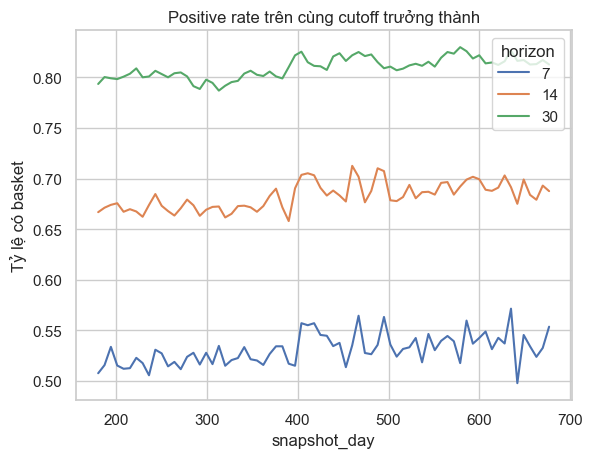

In [22]:
last_day = int(daily.DAY.max())
common_days = list(range(180, last_day - 30 + 1, 7))
hh_day = daily[['household_key','DAY','baskets']]
matrix = (hh_day.pivot(index='household_key', columns='DAY', values='baskets')
          .reindex(columns=range(last_day + 1), fill_value=0).fillna(0).to_numpy())
cum = np.cumsum(matrix, axis=1)
first = np.where(matrix > 0, np.arange(last_day + 1), last_day + 1).min(axis=1)
horizon_records = []
for h in (7,14,30):
    for s in common_days:
        eligible = first <= s
        labels = (cum[:, s+h] - cum[:, s])[eligible] > 0
        horizon_records.append({'horizon': h, 'snapshot_day': s, 'rate': labels.mean(),
                                'households': int(eligible.sum())})
horizon_rates = pd.DataFrame(horizon_records)
display(horizon_rates.groupby('horizon').rate.agg(['mean','min','max','std']))
sns.lineplot(data=horizon_rates, x='snapshot_day', y='rate', hue='horizon', palette='deep')
plt.title('Positive rate trên cùng cutoff trưởng thành'); plt.ylabel('Tỷ lệ có basket'); plt.show()

# 4. Chia train / validation / test theo thời gian

Mỗi tập gồm nhiều snapshot tuần; giữa các tập chừa một snapshot. Label training phải trưởng thành trước snapshot validation/test. Cùng household có thể xuất hiện ở nhiều giai đoạn: kết quả đo khả năng dự báo tương lai cho nhóm khách đã biết, không đo generalization sang household hoàn toàn mới.

In [24]:
train_mask, val_mask, test_mask, split = temporal_split(snapshots, cfg)
display(pd.DataFrame({k:v for k,v in split.items() if isinstance(v, dict)}).T)
print('Embargo snapshots:', split['embargo_days'])
assert split['train']['snapshot_max'] + cfg.horizon_days < split['validation']['snapshot_min']
assert split['validation']['snapshot_max'] + cfg.horizon_days < split['test']['snapshot_min']
train = snapshots.loc[train_mask].copy()
val = snapshots.loc[val_mask].copy()
test = snapshots.loc[test_mask].copy()
print('Train target rate:', train[target].mean(), '| Validation:', val[target].mean())

Embargo snapshots: [544, 628]
Train target rate: 0.527935671703868 | Validation: 0.5393740902474526


,snapshot_min,snapshot_max,snapshots,rows
train,180,537,52,129834
validation,551,621,11,27480
test,635,698,10,24994


# 5. Feature engineering và EDA trên train

Các nhóm feature gồm recency/cadence, frequency, spend, basket size, category, brand, discount và diversity. Để tránh phụ thuộc vào thông tin nhân khẩu học không có ngày hiệu lực, mô hình của notebook chỉ dùng feature hành vi. Toàn bộ biểu đồ và phép chọn dưới đây dùng **train**.

In [26]:
features = ['recency_days','active_days_30d','active_days_90d','baskets_30d',
            'spend_30d','avg_basket_value_30d','line_items_30d',
            'discount_rate_30d','private_label_spend_share_90d',
            'grocery_spend_share_90d','fuel_spend_share_90d',
            'product_day_diversity_per_active_day_90d','recency_to_cadence']
assert all(f in train.columns for f in features)
display(train[features].describe(percentiles=[.05,.5,.95]).T)
display(train.groupby(target)[features].median().T.rename(columns={0:'Không mua',1:'Có mua'}))

,count,mean,std,min,5%,50%,95%,max
recency_days,129834.0,25.557404,54.979469,0.0,0.0,6.000000,134.000000,507.000000
active_days_30d,129834.0,4.175747,4.373536,0.0,0.0,3.000000,13.000000,30.000000
active_days_90d,129834.0,12.426699,12.230792,0.0,0.0,9.000000,37.000000,86.000000
baskets_30d,129834.0,5.137745,6.700841,0.0,0.0,3.000000,17.000000,109.000000
spend_30d,129834.0,149.894775,191.294189,0.0,0.0,82.215000,537.389011,2810.770020
avg_basket_value_30d,129834.0,26.767830,28.718544,0.0,0.0,20.052584,80.002502,467.195007
line_items_30d,129834.0,48.359283,58.365299,0.0,0.0,28.000000,166.000000,647.000000
discount_rate_30d,129834.0,0.122049,0.095517,0.0,0.0,0.122244,0.285919,0.825005
private_label_spend_share_90d,129834.0,0.252157,0.177812,0.0,0.0,0.237005,0.553915,1.000000
grocery_spend_share_90d,129834.0,0.476538,0.222957,0.0,0.0,0.509394,0.792639,1.000000


target_purchase_next_7d,Không mua,Có mua
recency_days,15.000000,3.000000
active_days_30d,1.000000,5.000000
active_days_90d,4.000000,15.000000
baskets_30d,1.000000,6.000000
spend_30d,22.310001,161.429993
avg_basket_value_30d,11.392000,25.319443
line_items_30d,7.000000,55.000000
discount_rate_30d,0.078997,0.140379
private_label_spend_share_90d,0.195465,0.264811
grocery_spend_share_90d,0.489082,0.520390


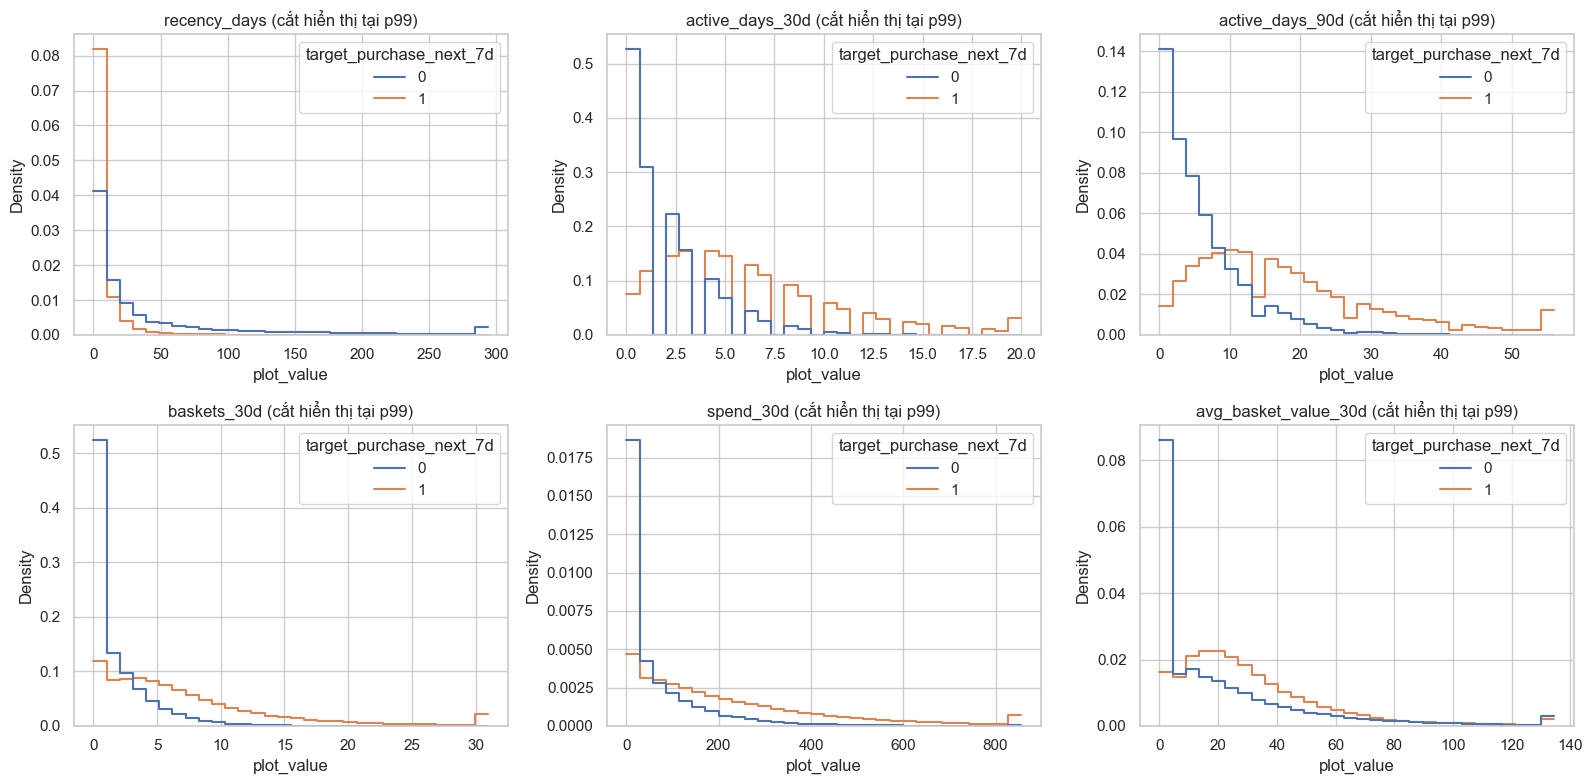

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16,8))
for ax, col in zip(axes.flat, features[:6]):
    upper = train[col].quantile(.99)
    sns.histplot(data=train.assign(plot_value=train[col].clip(upper=upper)), x='plot_value',
                 hue=target, stat='density', common_norm=False, bins=30,
                 element='step', fill=False, ax=ax)
    ax.set_title(col + ' (cắt hiển thị tại p99)')
plt.tight_layout(); plt.show()

Histogram được cắt ở p99 chỉ để dễ nhìn; model vẫn dùng feature gốc. Sự khác nhau giữa hai phân phối là association trên train, chưa phải quan hệ nhân quả.

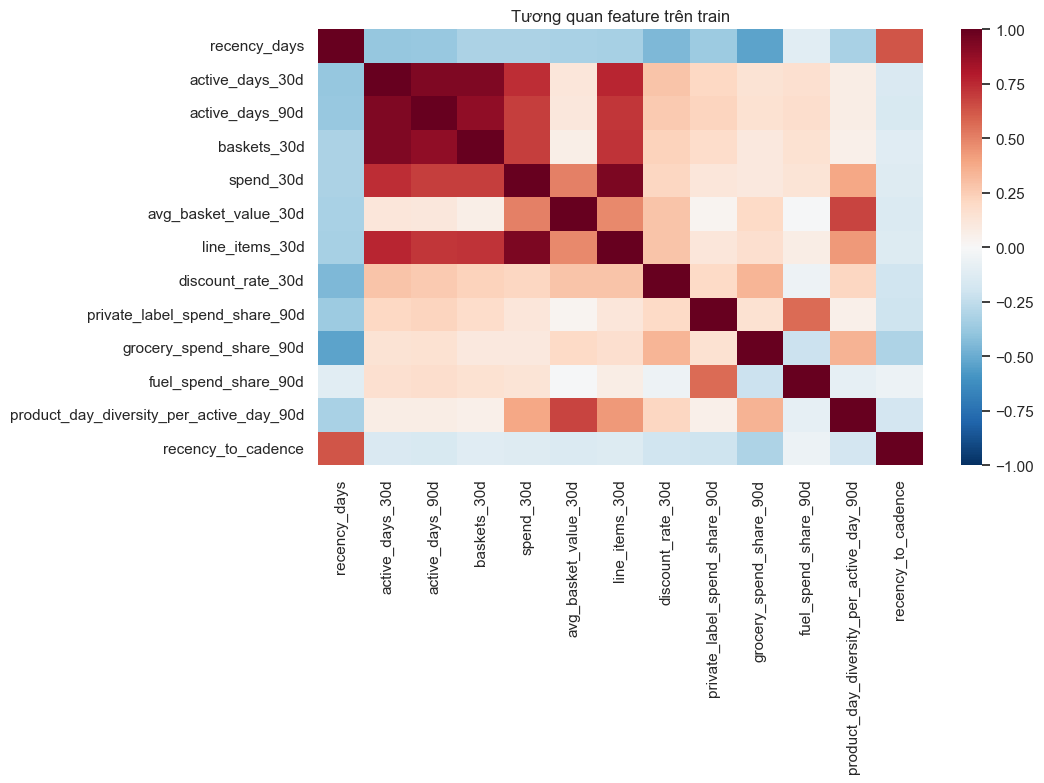

In [29]:
fig, ax = plt.subplots(figsize=(11,8))
sns.heatmap(train[features].corr(), center=0, cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Tương quan feature trên train'); plt.tight_layout(); plt.show()

## Một ví dụ kiểm tra confounding: fuel và tần suất mua

So sánh tỷ lệ mua giữa household có/không fuel, sau đó chia theo mức activity 90 ngày. Đây là phép kiểm tra mô tả; stratification không điều chỉnh mọi confounder và không xác lập tác động của fuel.

In [31]:
eda = train[['active_days_90d','fuel_spend_90d',target]].copy()
eda['fuel_buyer'] = eda.fuel_spend_90d.gt(0)
eda['activity_band'] = pd.qcut(eda.active_days_90d, 4, duplicates='drop')
print('Association thô:')
display(eda.groupby('fuel_buyer')[target].agg(['mean','size']))
print('Theo nhóm activity:')
display(eda.groupby(['activity_band','fuel_buyer'], observed=True)[target].agg(['mean','size']))
print('Chênh lệch thô cần được đọc cùng activity và số mẫu; không diễn giải là quan hệ nhân quả.')

Association thô:
Theo nhóm activity:
Chênh lệch thô cần được đọc cùng activity và số mẫu; không diễn giải là quan hệ nhân quả.


,mean,size
fuel_buyer,,
False,0.450535,94370
True,0.733899,35464


mean   size
activity_band fuel_buyer                 
(-0.001, 3.0] False       0.158729  31053
              True        0.219547   1412
(3.0, 9.0]    False       0.409350  29156
              True        0.418891   5844
(9.0, 18.0]   False       0.667088  21375
              True        0.703115  11139
(18.0, 86.0]  False       0.891131  12786
              True        0.904388  17069

# 6. Baseline và rolling-origin cross-validation

Baseline một biến xếp hạng theo **recency thấp hơn → propensity cao hơn**. Baseline này không cần fit. So sánh với logistic regression và histogram gradient boosting trên cùng ba temporal folds; preprocessing chỉ fit trên phần train của từng fold. PR-AUC được hiểu cùng prevalence, ROC-AUC là thước đo bổ sung.

In [33]:
folds = rolling_origin_folds(snapshots, split['validation']['snapshot_min'])
models = {
    'logistic': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                              LogisticRegression(C=0.3, max_iter=500, random_state=42)),
    'hgb_regularized': make_pipeline(SimpleImputer(strategy='median'),
        HistGradientBoostingClassifier(max_iter=120, learning_rate=.07, max_leaf_nodes=15,
                                       min_samples_leaf=80, l2_regularization=5,
                                       early_stopping=False, random_state=42))}
records = []
for fold in folds:
    ft = snapshots[snapshots.snapshot_day.isin(fold['train_days'])]
    fv = snapshots[snapshots.snapshot_day.isin(fold['validation_days'])]
    assert max(fold['train_days']) + cfg.horizon_days < min(fold['validation_days'])
    for name, model in [('recency_rule', None), *models.items()]:
        if model is None:
            score = -fv.recency_days.to_numpy()
        else:
            fitted = clone(model).fit(ft[features], ft[target])
            score = fitted.predict_proba(fv[features])[:,1]
        records.append({'fold':fold['fold'], 'model':name,
                        'train_end':max(fold['train_days']), 'val_start':min(fold['validation_days']),
                        'val_end':max(fold['validation_days']), 'prevalence':fv[target].mean(),
                        'pr_auc':average_precision_score(fv[target], score),
                        'roc_auc':roc_auc_score(fv[target], score)})
cv_results = pd.DataFrame(records)
display(cv_results)
display(cv_results.groupby('model')[['pr_auc','roc_auc']].agg(['mean','std']).sort_values(('pr_auc','mean'), ascending=False))
means = cv_results.groupby('model').pr_auc.mean()
print(f"PR-AUC trung bình: recency={means['recency_rule']:.4f}, logistic={means['logistic']:.4f}, HGB={means['hgb_regularized']:.4f}.")

PR-AUC trung bình: recency=0.7251, logistic=0.8516, HGB=0.8553.


,fold,model,train_end,val_start,val_end,prevalence,pr_auc,roc_auc
0,1,recency_rule,376,390,432,0.541621,0.731279,0.756825
1,1,logistic,376,390,432,0.541621,0.859829,0.836643
2,1,hgb_regularized,376,390,432,0.541621,0.863331,0.840747
3,2,recency_rule,432,446,488,0.534370,0.723410,0.748675
4,2,logistic,432,446,488,0.534370,0.843209,0.822922
5,2,hgb_regularized,432,446,488,0.534370,0.846367,0.826571
6,3,recency_rule,488,502,544,0.533169,0.720623,0.751465
7,3,logistic,488,502,544,0.533169,0.851797,0.832545
8,3,hgb_regularized,488,502,544,0.533169,0.856136,0.836587


pr_auc             roc_auc          
                     mean       std      mean       std
model                                                  
hgb_regularized  0.855278  0.008515  0.834635  0.007287
logistic         0.851612  0.008311  0.830703  0.007043
recency_rule     0.725104  0.005526  0.752322  0.004142

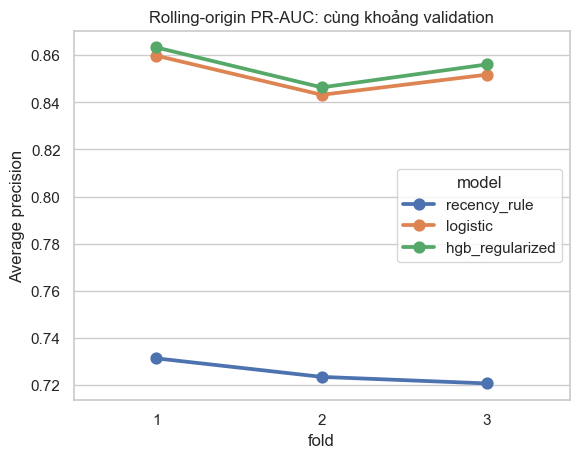

In [34]:
sns.pointplot(data=cv_results, x='fold', y='pr_auc', hue='model', markers='o')
plt.title('Rolling-origin PR-AUC: cùng khoảng validation'); plt.ylabel('Average precision'); plt.show()

Chọn theo mean PR-AUC trên ba folds, với tie-breaker là mô hình đơn giản hơn. Ba folds không đủ để khẳng định sai khác nhỏ có ý nghĩa thống kê; bảng theo từng fold cho thấy variation và tính phụ thuộc thời gian.

In [36]:
cv_mean = cv_results[cv_results.model != 'recency_rule'].groupby('model').pr_auc.mean()
winner = cv_mean.sort_values(ascending=False).index[0]
if abs(cv_mean['logistic'] - cv_mean['hgb_regularized']) < 0.002:
    winner = 'logistic'
print('Model khóa trước validation/test:', winner)
champion = clone(models[winner]).fit(train[features], train[target])

Model khóa trước validation/test: hgb_regularized


# 7. Calibration trên validation

Probability ranking và calibration là hai yêu cầu khác nhau. Fit Platt scaling trên validation; báo cáo validation sau calibration chỉ là in-sample diagnostic cho calibrator. Ngưỡng 0.5 dưới đây chỉ minh họa, không phải ngưỡng lợi nhuận tối ưu.

In [38]:
p_val_raw = champion.predict_proba(val[features])[:,1]
calibrator = fit_calibrator(p_val_raw, val[target].to_numpy())
p_val = calibrate(calibrator, p_val_raw)
display(pd.DataFrame({'uncalibrated':[brier_score_loss(val[target],p_val_raw)],
                      'calibrated_in_sample':[brier_score_loss(val[target],p_val)]},
                     index=['validation Brier']))

,uncalibrated,calibrated_in_sample
validation Brier,0.165136,0.165139


# 8. Temporal holdout — đánh giá sau khi khóa model

Trong notebook này test không tham gia chọn feature/model/calibration; vì đã được xem ở V2 trước đây, không gọi đây là untouched test ở cấp toàn dự án. Cần một giai đoạn dữ liệu mới cho xác nhận độc lập.

In [40]:
p_test = calibrate(calibrator, champion.predict_proba(test[features])[:,1])
y_test = test[target].to_numpy()
recency_test = -test.recency_days.to_numpy()
test_metrics = pd.DataFrame({
    'prevalence':[y_test.mean()],
    'PR-AUC':[average_precision_score(y_test,p_test)],
    'ROC-AUC':[roc_auc_score(y_test,p_test)],
    'Brier':[brier_score_loss(y_test,p_test)],
    'recency PR-AUC':[average_precision_score(y_test,recency_test)]})
display(test_metrics)
print('Đây là đánh giá trên household đã biết; cần một giai đoạn mới để kiểm định độc lập.')

Đây là đánh giá trên household đã biết; cần một giai đoạn mới để kiểm định độc lập.


,prevalence,PR-AUC,ROC-AUC,Brier,recency PR-AUC
0,0.532168,0.850544,0.830358,0.167867,0.718294


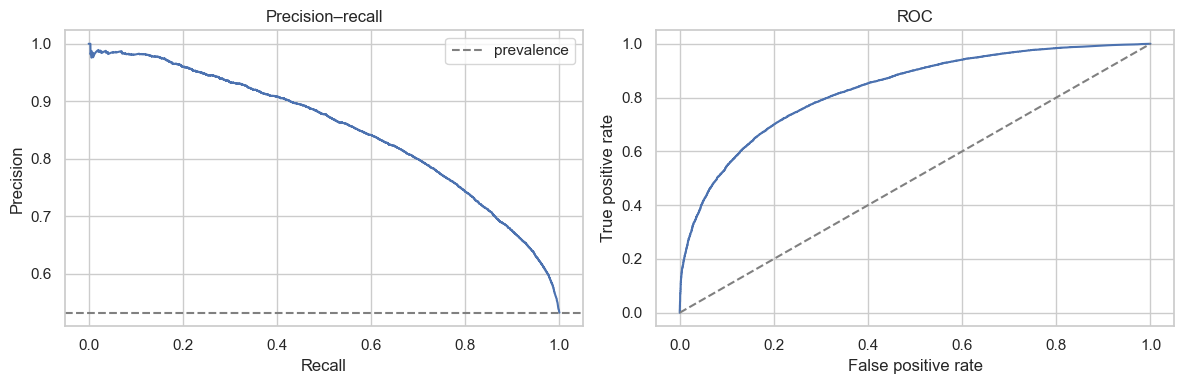

In [41]:
precision, recall, _ = precision_recall_curve(y_test,p_test)
fpr, tpr, _ = roc_curve(y_test,p_test)
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(recall,precision); ax[0].axhline(y_test.mean(),ls='--',color='gray',label='prevalence')
ax[0].set(title='Precision–recall',xlabel='Recall',ylabel='Precision'); ax[0].legend()
ax[1].plot(fpr,tpr); ax[1].plot([0,1],[0,1],'--',color='gray')
ax[1].set(title='ROC',xlabel='False positive rate',ylabel='True positive rate')
plt.tight_layout(); plt.show()

,n,predicted,observed
decile,,,
"(0.0382, 0.142]",2500,0.085177,0.082400
"(0.142, 0.245]",2499,0.194069,0.189276
"(0.245, 0.338]",2499,0.291969,0.294918
"(0.338, 0.434]",2500,0.384271,0.385600
"(0.434, 0.549]",2499,0.492410,0.461385
"(0.549, 0.653]",2499,0.601399,0.584234
"(0.653, 0.759]",2500,0.704689,0.688400
"(0.759, 0.848]",2499,0.805264,0.792317
"(0.848, 0.928]",2499,0.888038,0.878351


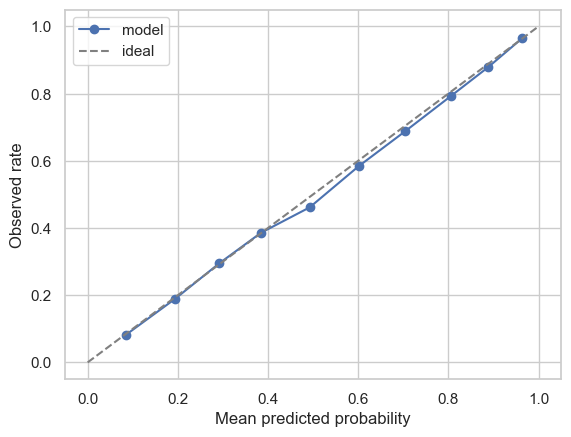

In [42]:
prediction = test[['household_key','snapshot_day',target,'recency_days','active_days_90d']].copy()
prediction['probability'] = p_test
prediction['decile'] = pd.qcut(prediction.probability, 10, duplicates='drop')
calibration = prediction.groupby('decile', observed=True).agg(
    n=(target,'size'), predicted=('probability','mean'), observed=(target,'mean'))
display(calibration)
plt.plot(calibration.predicted,calibration.observed,'o-',label='model')
plt.plot([0,1],[0,1],'--',color='gray',label='ideal')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed rate'); plt.legend(); plt.show()

## Capacity: chọn top-K theo từng tuần

Tính top-K riêng cho từng snapshot để phản ánh capacity của chiến dịch tuần. Một household có thể xuất hiện nhiều tuần, do đó số contact là household-snapshot, không phải số người duy nhất hay số giao dịch tăng thêm.

,capacity,contacts,buyers_observed,precision,recall,lift
0,0.05,1250,1227,0.981600,0.092249,1.844531
1,0.10,2500,2411,0.964400,0.181265,1.812211
2,0.20,5000,4613,0.922600,0.346816,1.733664
3,0.30,7500,6590,0.878667,0.495451,1.651109
4,0.50,12500,9771,0.781680,0.734606,1.468860
5,1.00,24994,13301,0.532168,1.000000,1.000000


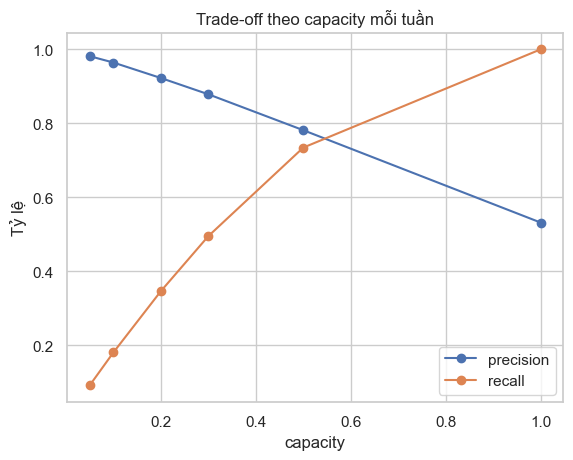

In [44]:
capacity_rows = []
for fraction in (.05,.10,.20,.30,.50,1.0):
    ordered = prediction.sort_values(['snapshot_day','probability'], ascending=[True,False])
    selected = pd.concat([g.head(max(1, int(np.ceil(len(g)*fraction))))
                          for _, g in ordered.groupby('snapshot_day')])
    base = prediction[target].mean()
    capacity_rows.append({'capacity':fraction, 'contacts':len(selected),
                          'buyers_observed':int(selected[target].sum()),
                          'precision':selected[target].mean(),
                          'recall':selected[target].sum()/prediction[target].sum(),
                          'lift':selected[target].mean()/base})
capacity = pd.DataFrame(capacity_rows)
display(capacity)
capacity.plot(x='capacity',y=['precision','recall'],marker='o',title='Trade-off theo capacity mỗi tuần')
plt.ylabel('Tỷ lệ'); plt.show()

## Ổn định theo thời gian và theo nhóm recency

PR-AUC phụ thuộc prevalence nên cần đọc cùng tỷ lệ positive của từng tuần. Phân tích nhóm có tính mô tả, các snapshot của cùng household có liên quan với nhau.

,rows,prevalence,pr_auc,brier
snapshot_day,,,,
635,2499,0.571429,0.864594,0.167865
642,2499,0.497799,0.816666,0.172084
649,2499,0.545418,0.862581,0.164550
656,2499,0.534214,0.841717,0.172856
663,2499,0.523810,0.854569,0.166734
670,2499,0.532613,0.846367,0.172659
677,2500,0.553600,0.871618,0.160855
684,2500,0.530000,0.862530,0.162250
691,2500,0.525200,0.843968,0.173770


,rows,observed,predicted
recency_band,,,
"(-1.0, 7.0]",14346,0.698243,0.708973
"(7.0, 14.0]",3302,0.502120,0.501621
"(14.0, 30.0]",2947,0.338649,0.361495
"(30.0, 60.0]",1902,0.212408,0.213341
"(60.0, inf]",2497,0.089708,0.090538


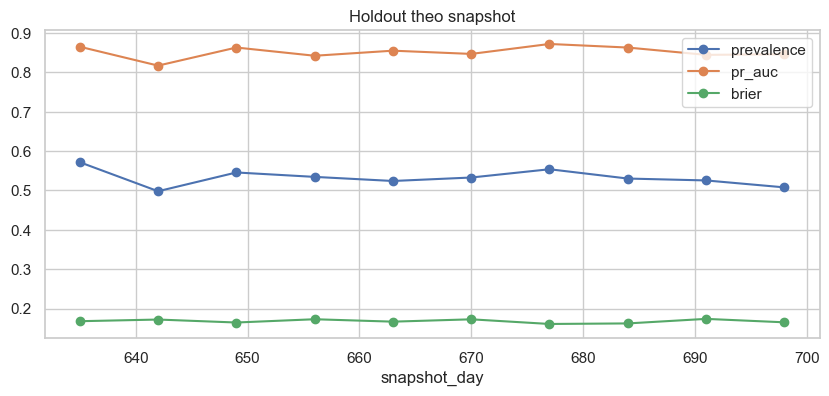

In [46]:
weekly = pd.DataFrame([{'snapshot_day': day, 'rows':len(g),
    'prevalence':g[target].mean(), 'pr_auc':average_precision_score(g[target],g.probability),
    'brier':brier_score_loss(g[target],g.probability)}
    for day, g in prediction.groupby('snapshot_day')]).set_index('snapshot_day')
display(weekly)
weekly[['prevalence','pr_auc','brier']].plot(marker='o', figsize=(10,4),title='Holdout theo snapshot')
plt.show()
prediction['recency_band'] = pd.cut(prediction.recency_days,[-1,7,14,30,60,np.inf])
display(prediction.groupby('recency_band', observed=True).agg(
    rows=(target,'size'), observed=(target,'mean'), predicted=('probability','mean')))

# 9. Đưa kết quả vào vận hành và giới hạn

- Ranking top-K hỗ trợ phân bổ capacity; xác suất cao không đồng nghĩa tác động của coupon cao.
- Trước pilot: xác nhận định nghĩa basket hợp lệ, data availability tại cutoff, chi phí contact và contribution margin.
- Randomized treatment/control cần thiết để đo incremental purchase/margin.
- Monitor freshness, schema, calibration, PR-AUC và lift theo thời gian khi label mature.
- Dataset là panel frequent shoppers của một retailer; không tự động suy rộng sang khách mới hoặc toàn thị trường.
- Cần dữ liệu tương lai chưa từng dùng trong quá trình phát triển để kiểm định cuối độc lập.

**Tái lập:** chạy các cell theo thứ tự từ thư mục project root hoặc `notebooks`; đầu vào là tám CSV trong `sample_data/dunnhumby`. Lần chạy đầy đủ đọc file causal khoảng 664 MB và huấn luyện 6 mô hình qua temporal folds.